In [67]:
import numpy as np
import pandas as pd
import time
import shap
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_val_score

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [68]:
data = pd.read_csv("dataset_final_SO.csv")
data.head()



,id,serie,nom_spe1,nom_spe2,note_maths,note_francais,note_anglais,note_philo,note_hg,note_spe1,...,score_S,score_E,score_C,code_holland,stress,social,autonomie,adaptabilite,branche,categorie
0,1,L1,LV2,—,11.71,14.19,14.99,16.39,14.44,13.33,...,4.66,4.79,3.78,ESC,3.49,4.65,3.68,3.97,Sciences Politiques,Droit & Sciences Politiques
1,2,S1,Physique-Chimie,—,13.56,14.46,15.57,12.72,13.78,17.23,...,4.24,3.11,3.66,ISR,4.54,4.49,3.73,3.97,Médecine,Sciences de la Santé
2,3,L1,LV2,—,11.01,17.88,18.04,16.04,13.55,15.41,...,4.50,4.46,3.70,SEC,3.85,3.98,3.67,4.25,Sciences Politiques,Droit & Sciences Politiques
3,4,L2,LV2,—,8.61,17.35,14.43,13.62,17.03,16.96,...,4.43,4.69,3.35,ESI,3.47,4.55,3.76,3.92,Sciences Politiques,Droit & Sciences Politiques
4,5,L2,LV2,—,8.05,13.03,12.87,14.79,15.17,12.72,...,4.82,2.99,2.44,SIA,3.35,4.47,3.38,5.00,Sociologie,Sciences Humaines & Sociales


In [69]:
data.shape

(6830, 27)

In [70]:
data.dtypes

id                 int64
serie                str
nom_spe1             str
nom_spe2             str
note_maths       float64
note_francais    float64
note_anglais     float64
note_philo       float64
note_hg          float64
note_spe1        float64
note_spe2        float64
moy_sciences     float64
moy_lettres      float64
moy_globale      float64
score_R          float64
score_I          float64
score_A          float64
score_S          float64
score_E          float64
score_C          float64
code_holland         str
stress           float64
social           float64
autonomie        float64
adaptabilite     float64
branche              str
categorie            str
dtype: object

In [71]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6830 entries, 0 to 6829
Data columns (total 27 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             6830 non-null   int64  
 1   serie          6830 non-null   str    
 2   nom_spe1       6830 non-null   str    
 3   nom_spe2       6830 non-null   str    
 4   note_maths     6830 non-null   float64
 5   note_francais  6830 non-null   float64
 6   note_anglais   6830 non-null   float64
 7   note_philo     6830 non-null   float64
 8   note_hg        6830 non-null   float64
 9   note_spe1      6830 non-null   float64
 10  note_spe2      6830 non-null   float64
 11  moy_sciences   6830 non-null   float64
 12  moy_lettres    6830 non-null   float64
 13  moy_globale    6830 non-null   float64
 14  score_R        6830 non-null   float64
 15  score_I        6830 non-null   float64
 16  score_A        6830 non-null   float64
 17  score_S        6830 non-null   float64
 18  score_E        6830

In [72]:
print (data.isnull().sum())

id               0
serie            0
nom_spe1         0
nom_spe2         0
note_maths       0
note_francais    0
note_anglais     0
note_philo       0
note_hg          0
note_spe1        0
note_spe2        0
moy_sciences     0
moy_lettres      0
moy_globale      0
score_R          0
score_I          0
score_A          0
score_S          0
score_E          0
score_C          0
code_holland     0
stress           0
social           0
autonomie        0
adaptabilite     0
branche          0
categorie        0
dtype: int64


Suppression des colonnes inutiles

In [73]:
data = data.drop(columns=['id'])

Nous allons faire une prédiction a 2 niveaux, pour le premier niveau, nous allons faire des predictions juste avec la variable catégorie sans oublier d'enlever la variable branche dans X, et ensuite avec la variable branche

Pour pouvoir réellement chaîner le niveau 1 (catégorie) et le niveau 2 (branche) lors de l'évaluation finale, il faut que les deux modèles soient évalués sur exactement le même ensemble de lycéens. On réalise donc un seul split train/val/test (70/15/15) stratifié sur la vraible branche, et on en dérive les features/labels des 2 niveaux.

In [74]:
idx_train, idx_temp = train_test_split(
    data.index,
    test_size=0.30,
    random_state=42,
    stratify=data['branche']
)

idx_val, idx_test = train_test_split(
    idx_temp,
    test_size=0.50,
    random_state=42,
    stratify=data.loc[idx_temp, 'branche']
)

data_train = data.loc[idx_train].reset_index(drop=True)
data_val   = data.loc[idx_val].reset_index(drop=True)
data_test  = data.loc[idx_test].reset_index(drop=True)

print("Train :", data_train.shape)
print("Val   :", data_val.shape)
print("Test  :", data_test.shape)

Train : (4781, 26)
Val   : (1024, 26)
Test  : (1025, 26)


Séparation des variables cibles 

In [75]:
X_train_cat = data_train.drop(columns=['categorie', 'branche'])
X_val_cat   = data_val.drop(columns=['categorie', 'branche'])
X_test_cat  = data_test.drop(columns=['categorie', 'branche'])

y_train_cat = data_train['categorie']
y_val_cat   = data_val['categorie']
y_test_cat  = data_test['categorie']

Nous allons procéder à l'encodage de y avec LabelEncoder car XGBoost ne prend pas en compte le texte, ensuite nous ferons un inverse statement lors des prédictions.

In [76]:
label_encoder_cat = LabelEncoder()

y_train_cat = label_encoder_cat.fit_transform(y_train_cat)
y_val_cat   = label_encoder_cat.transform(y_val_cat)
y_test_cat  = label_encoder_cat.transform(y_test_cat)

In [77]:
#vérification des correspondances

for i, classe in enumerate(label_encoder_cat.classes_):
    print(i, "->", classe)

0 -> Agriculture & Environnement
1 -> Arts & Culture
2 -> Droit & Sciences Politiques
3 -> Lettres & Communication
4 -> Multimédia & Création Numérique
5 -> Sciences & Technologies
6 -> Sciences Humaines & Sociales
7 -> Sciences de la Santé
8 -> Sciences Économiques & Gestion


Les modèles ne comprenant pas le texte, il va falloir encoder les variables catégorielles, exemple : serie, nom_spe1 etc...
tout d'abord il faut identifier ces variables, ensuite nous allons gérer l'encodage avec OneHotEncoder.

In [78]:
cat_cols= X_train_cat.select_dtypes(include=['object', 'str']).columns
num_cols= X_train_cat.select_dtypes(include=['int64', 'float64']).columns

In [79]:
preprocessor_cat = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

Application du prétraitement

In [80]:
#fit sur train
X_train_cat_processed= preprocessor_cat.fit_transform(X_train_cat)

#transform seulement sur val et test
X_val_cat_processed = preprocessor_cat.transform(X_val_cat)
X_test_cat_processed = preprocessor_cat.transform(X_test_cat)


Nous allons utilisé SMOTE pour corriger le déséquilibre des classes dans le dataset. Cette méthode génère artificiellement de nouveaux exemples pour les classes minoritaires afin d’éviter que le modèle soit biaisé vers les classes majoritaires.

In [81]:
print(pd.Series (y_train_cat).value_counts())

5    1106
7     840
8     518
4     490
0     455
6     385
2     364
3     343
1     280
Name: count, dtype: int64


In [82]:
classes, counts = np.unique (y_train_cat, return_counts=True)
strat_smote = {}
for cl, co in zip(classes, counts):
    if co < 700 :
        strat_smote[cl]= 700
    else:
        strat_smote[cl]= co
print ("Stratégie planifiée :", strat_smote)

smote_cat= SMOTE(sampling_strategy=strat_smote, random_state=42)
X_train_cat_smote, y_train_cat_smote = smote_cat.fit_resample (
    X_train_cat_processed,
    y_train_cat
)

Stratégie planifiée : {np.int64(0): 700, np.int64(1): 700, np.int64(2): 700, np.int64(3): 700, np.int64(4): 700, np.int64(5): np.int64(1106), np.int64(6): 700, np.int64(7): np.int64(840), np.int64(8): 700}


Vérification après smote

In [83]:
print(pd.Series(y_train_cat_smote).value_counts())

5    1106
7     840
6     700
8     700
4     700
2     700
0     700
3     700
1     700
Name: count, dtype: int64


Logistic Regression

In [84]:
log_model = LogisticRegression (
    max_iter=1000,
    random_state=42
)

#Entrainement
log_model.fit(X_train_cat_smote, y_train_cat_smote)

#predict avec val
y_pred_log = log_model.predict(X_val_cat_processed)

#Accuracy
accuracy_log = accuracy_score(y_val_cat, y_pred_log)

#F1-score
f1_log= f1_score (
    y_val_cat,
    y_pred_log,
    average='macro'
)

KNN 

In [85]:
knn_model= KNeighborsClassifier(
    n_neighbors=5
)

#Entrainement
knn_model.fit(X_train_cat_smote, y_train_cat_smote)

#predict avec val
y_pred_knn= knn_model.predict(X_val_cat_processed)

#accuracy
accuracy_knn= accuracy_score(y_val_cat, y_pred_knn)

#F1-score
f1_knn= f1_score (
    y_val_cat,
    y_pred_knn,
    average='macro'
)

Random Forest

In [86]:
rf_model= RandomForestClassifier(
    random_state=42
)

#Entrainement
rf_model.fit(X_train_cat_smote, y_train_cat_smote)

#predict avec val
y_pred_rf = rf_model.predict(X_val_cat_processed)

#Accuracy
accuracy_rf= accuracy_score( y_val_cat, y_pred_rf)

#F1-score
f1_rf= f1_score (
    y_val_cat,
    y_pred_rf,
    average= 'macro'
)

XGBoost

In [87]:
xgb_model= XGBClassifier(
    random_state=42,
    eval_metric='mlogloss'
)

#Entrainement
xgb_model.fit(X_train_cat_smote, y_train_cat_smote)

#predict avec val
y_pred_xgb= xgb_model.predict(X_val_cat_processed)

#accuracy
accuracy_xgb= accuracy_score(y_val_cat, y_pred_xgb)

#F1-score
f1_xgb =f1_score (
    y_val_cat,
    y_pred_xgb,
    average='macro'
)

Reconversion en texte

In [88]:
pred_log_text = label_encoder_cat.inverse_transform(y_pred_log)
pred_knn_text = label_encoder_cat.inverse_transform(y_pred_knn)
pred_rf_text = label_encoder_cat.inverse_transform(y_pred_rf)
pred_xgb_text = label_encoder_cat.inverse_transform(y_pred_xgb)

Comparaison Accuracy

In [89]:
print("ACCURACY")

print("Logistic Regression :", accuracy_log)

print("KNN :", accuracy_knn)

print("Random Forest :", accuracy_rf)

print("XGBoost :", accuracy_xgb)


ACCURACY
Logistic Regression : 0.98828125
KNN : 0.984375
Random Forest : 0.99609375
XGBoost : 0.9931640625


Comparaison F1-Score

In [90]:
print("F1-score")

print("Logistic Regression:", f1_log)

print("KNN:", f1_knn)

print("Random Forest:", f1_rf)

print("XGBoost:", f1_xgb)

F1-score
Logistic Regression: 0.9843984720690488
KNN: 0.9803672787141531
Random Forest: 0.9948606924509451
XGBoost: 0.9911710704130792


Nous allons maintenant procéder à l'entrainement du niveau 2

In [91]:
X_train_branche = data_train.drop(columns=['branche'])
X_val_branche   = data_val.drop(columns=['branche'])
X_test_branche  = data_test.drop(columns=['branche'])

y_train_branche = data_train['branche']
y_val_branche   = data_val['branche']
y_test_branche  = data_test['branche']

In [92]:
label_encoder_branche = LabelEncoder()

y_train_branche = label_encoder_branche.fit_transform(y_train_branche)
y_val_branche   = label_encoder_branche.transform(y_val_branche)
y_test_branche  = label_encoder_branche.transform(y_test_branche)

In [93]:
cat_cols= X_train_branche.select_dtypes(include=['object', 'str']).columns
num_cols= X_train_branche.select_dtypes(include=['int64', 'float64']).columns

In [94]:
preprocessor_branche = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

In [95]:
X_train_branche_processed= preprocessor_branche.fit_transform(X_train_branche)

#transform seulement sur val et test
X_val_branche_processed = preprocessor_branche.transform(X_val_branche)
X_test_branche_processed = preprocessor_branche.transform(X_test_branche)

In [96]:
print(pd.Series (y_train_branche).value_counts())

25    224
16    224
11    196
14    182
29    168
7     154
20    154
23    140
32    140
12    126
4     126
8     126
9     126
34    126
1     126
21    112
15    112
36    112
42    112
13    105
38    105
2      98
37     98
22     91
31     84
3      84
0      84
19     70
30     70
35     70
44     70
18     70
6      70
10     70
17     70
33     70
5      70
24     70
26     70
27     70
41     70
40     70
43     70
39     63
28     63
Name: count, dtype: int64


In [97]:
classes, counts = np.unique (y_train_branche, return_counts=True)
strat_smote = {}
for cl, co in zip(classes, counts):
    if co < 80 :
        strat_smote[cl]= 80
    else:
        strat_smote[cl]= co
#print ("Stratégie planifiée :", strat_smote)

smote_branche = SMOTE(sampling_strategy=strat_smote, random_state=42)
X_train_branche_smote, y_train_branche_smote = smote_branche.fit_resample (
    X_train_branche_processed,
    y_train_branche
)

In [98]:
print(pd.Series(y_train_branche_smote).value_counts())

25    224
16    224
11    196
14    182
29    168
7     154
20    154
23    140
32    140
12    126
4     126
8     126
9     126
34    126
1     126
21    112
15    112
36    112
42    112
13    105
38    105
2      98
37     98
22     91
31     84
3      84
0      84
19     80
30     80
35     80
44     80
18     80
6      80
10     80
17     80
33     80
5      80
24     80
26     80
27     80
41     80
39     80
28     80
40     80
43     80
Name: count, dtype: int64


Logistic Regression 2

In [99]:
log_model2 = LogisticRegression (
    max_iter=1000,
    random_state=42
)

#Entrainement
log_model2.fit(X_train_branche_smote, y_train_branche_smote)

#predict avec val
y_pred_log2 = log_model2.predict(X_val_branche_processed)

#Accuracy
accuracy_log2 = accuracy_score(y_val_branche, y_pred_log2)

#F1-score
f1_log2= f1_score (
    y_val_branche,
    y_pred_log2,
    average='macro'
)

KNN 2

In [100]:
knn_model2= KNeighborsClassifier(
    n_neighbors=5
)

#Entrainement
knn_model2.fit(X_train_branche_smote, y_train_branche_smote)

#predict avec val
y_pred_knn2= knn_model2.predict(X_val_branche_processed)

#accuracy
accuracy_knn2= accuracy_score(y_val_branche, y_pred_knn2)

#F1-score
f1_knn2= f1_score (
    y_val_branche,
    y_pred_knn2,
    average='macro'
)

Random Forest 2

In [101]:
rf_model2= RandomForestClassifier(
    random_state=42
)

#Entrainement
rf_model2.fit(X_train_branche_smote, y_train_branche_smote)

#predict avec val
y_pred_rf2 = rf_model2.predict(X_val_branche_processed)

#Accuracy
accuracy_rf2= accuracy_score( y_val_branche, y_pred_rf2)

#F1-score
f1_rf2= f1_score (
    y_val_branche,
    y_pred_rf2,
    average= 'macro'
)

XGBoost 2

In [102]:
xgb_model2= XGBClassifier(
    random_state=42,
    eval_metric='mlogloss'
)

#Entrainement
xgb_model2.fit(X_train_branche_smote, y_train_branche_smote)

#predict avec val
y_pred_xgb2= xgb_model2.predict(X_val_branche_processed)

#accuracy
accuracy_xgb2= accuracy_score(y_val_branche, y_pred_xgb2)

#F1-score
f1_xgb2 =f1_score (
    y_val_branche,
    y_pred_xgb2,
    average='macro'
)

In [103]:
pred_log2_text = label_encoder_branche.inverse_transform(y_pred_log2)
pred_knn2_text = label_encoder_branche.inverse_transform(y_pred_knn2)
pred_rf2_text = label_encoder_branche.inverse_transform(y_pred_rf2)
pred_xgb2_text = label_encoder_branche.inverse_transform(y_pred_xgb2)

In [104]:
print("ACCURACY")

print("Logistic Regression :", accuracy_log2)

print("KNN :", accuracy_knn2)

print("Random Forest :", accuracy_rf2)

print("XGBoost :", accuracy_xgb2)


ACCURACY
Logistic Regression : 0.9521484375
KNN : 0.8603515625
Random Forest : 0.9599609375
XGBoost : 0.9462890625


In [105]:
print("F1-score")

print("Logistic Regression:", f1_log2)

print("KNN:", f1_knn2)

print("Random Forest:", f1_rf2)

print("XGBoost:", f1_xgb2)

F1-score
Logistic Regression: 0.9436995222683804
KNN: 0.8445771431372877
Random Forest: 0.9539095218280972
XGBoost: 0.9376018525662524


Matrice de Confusion du Niveau 2

En comparant les accuracy et les F1-score de nos 4 modèles, Random Forest possède le meilleur score, nous allons donc nous concentrer sur ce modèle pour la matrice

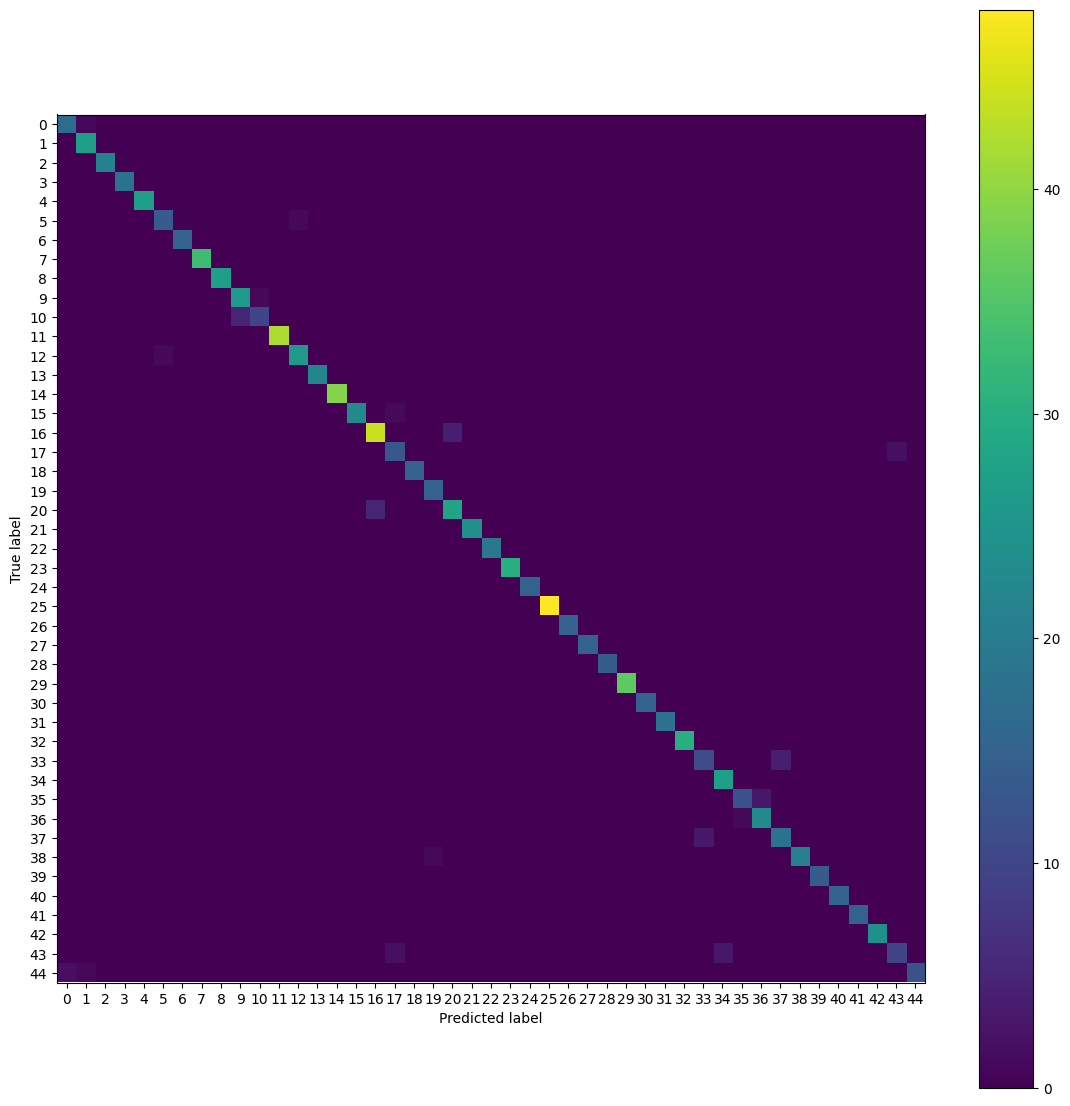

In [106]:
fig, ax = plt.subplots(figsize=(14, 14))

ConfusionMatrixDisplay.from_predictions(
    y_val_branche,
    y_pred_rf2,
    ax=ax,
    include_values=False
)

plt.show()

Classification Report

In [107]:


print(
    classification_report(
        y_val_branche,
        y_pred_rf2,
        target_names=label_encoder_branche.classes_
    )
)

                                  precision    recall  f1-score   support

                 Agroalimentaire       0.89      0.94      0.92        18
                       Agronomie       0.93      1.00      0.96        27
       Animation 3D & Jeux Vidéo       1.00      1.00      1.00        21
                      Beaux-Arts       1.00      1.00      1.00        18
                  Biotechnologie       1.00      1.00      1.00        27
          Commerce International       0.93      0.93      0.93        15
              Communication & RP       1.00      1.00      1.00        15
                   Cybersécurité       1.00      1.00      1.00        33
                Design Graphique       1.00      1.00      1.00        27
                     Droit Privé       0.84      0.96      0.90        27
                    Droit Public       0.91      0.67      0.77        15
      Développement Web & Mobile       1.00      1.00      1.00        42
    Entrepreneuriat & Management     

Validation croisée

Pour Logistic Regression

In [108]:
cv_log = cross_val_score(
    log_model2,
    X_train_branche_smote,
    y_train_branche_smote,
    cv=5,
    scoring='f1_macro'
)

print(cv_log)
print("Moyenne :", cv_log.mean())
print("Ecart-type :", cv_log.std())

[0.95329598 0.96282739 0.94969301 0.95627102 0.9557023 ]
Moyenne : 0.9555579418541266
Ecart-type : 0.004310175597343566


Pour KNN

In [109]:
cv_knn = cross_val_score(
    knn_model2,
    X_train_branche_smote,
    y_train_branche_smote,
    cv=5,
    scoring='f1_macro'
)

print(cv_knn)
print("Moyenne :", cv_knn.mean())
print("Ecart-type :", cv_knn.std())

[0.85422899 0.87395356 0.87107207 0.86118422 0.87433454]
Moyenne : 0.8669546771882384
Ecart-type : 0.007945325179517185


Pour Random Forest

In [110]:
cv_rf = cross_val_score(
    rf_model2,
    X_train_branche_smote,
    y_train_branche_smote,
    cv=5,
    scoring='f1_macro'
)

print(cv_rf)
print("Moyenne :", cv_rf.mean())
print("Ecart-type :", cv_rf.std())

[0.95881225 0.96267821 0.96052622 0.96359108 0.96276826]
Moyenne : 0.9616752037873013
Ecart-type : 0.0017543106703764033


Pour XGBoost

In [111]:
cv_xgb = cross_val_score(
    xgb_model2,
    X_train_branche_smote,
    y_train_branche_smote,
    cv=5,
    scoring='f1_macro'
)

print(cv_xgb)
print("Moyenne :", cv_xgb.mean())
print("Ecart-type :", cv_xgb.std())

[0.94193474 0.96145762 0.95400328 0.95440625 0.95333476]
Moyenne : 0.9530273293426779
Ecart-type : 0.006277956136126537


Une validation croisée a été réalisée afin d'évaluer la robustesse des modèles. Les résultats montrent que Random Forest a obtenu les meilleures performances avec un F1-score macro moyen de 96,17 %, suivi de la régression logistique (95,56 %) et de XGBoost (95,39 %). Les faibles écarts-types observés (< 0,6 %) indiquent une bonne stabilité des modèles et suggèrent une bonne capacité de généralisation.

                                Temps d'inférence

Pour Logistic Regression

In [112]:
temps_log = []

for i in range(1000):

    debut = time.perf_counter()

    log_model2.predict(X_test_branche_processed)

    fin = time.perf_counter()

    temps_log.append(fin - debut)

print("Temps moyen :", np.mean(temps_log)*1000, "ms")

Temps moyen : 1.2324200966395438 ms


Pour KNN

In [113]:
temps_knn = []

for i in range(1000):

    debut = time.perf_counter()

    knn_model2.predict(X_test_branche_processed)

    fin = time.perf_counter()

    temps_knn.append(fin - debut)

print("Temps moyen :", np.mean(temps_knn)*1000, "ms")

Temps moyen : 244.40442259749398 ms


Pour Random Forest

In [114]:
temps_rf = []

for i in range(1000):

    debut = time.perf_counter()

    rf_model2.predict(X_test_branche_processed)

    fin = time.perf_counter()

    temps_rf.append(fin - debut)

print("Temps moyen :", np.mean(temps_rf)*1000, "ms")

Temps moyen : 76.87331500183791 ms


Pour XGBoost

In [115]:
temps_xgb = []

for i in range(1000):

    debut = time.perf_counter()

    xgb_model2.predict(X_test_branche_processed)

    fin = time.perf_counter()

    temps_xgb.append(fin - debut)

print("Temps moyen :", np.mean(temps_xgb)*1000, "ms")

Temps moyen : 103.0956334026996 ms


                            SHAP

In [116]:
print(type(X_test_branche_processed))

<class 'scipy.sparse._csr.csr_matrix'>


Le résultat de ce code ci-dessus nous montre que X_test_branche_processed est une matrice sparse et cela est dû à l'utilisation du OneHotEncoder sur les variables. Mais Shap ne gère pas ce genre de matrice car il s'attend à des tableaux numérique. c'est pour cela que nous allons le convertir en tableau dense.

In [117]:
X_test_dense = X_test_branche_processed.toarray().astype(np.float64)

print(X_test_dense.shape)

(1025, 106)


Création de l'explainer

In [118]:
explainer = shap.TreeExplainer(rf_model2)

In [119]:
#Calcul 
shap_values = explainer.shap_values(
    X_test_dense[:50]
)
print (type(shap_values))

print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(50, 106, 45)


Calcul de l'importance moyenne des varibales

In [120]:
importance_globale = np.abs(shap_values).mean(axis=(0,2))

#Création du dataframe
feature_names = preprocessor_branche.get_feature_names_out()

importance_df = pd.DataFrame({
    'Variable': feature_names,
    'Importance': importance_globale
})

#Tri
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.head(20))

                                           Variable  Importance
13                                     num__score_S    0.007360
11                                     num__score_I    0.007255
12                                     num__score_A    0.006957
14                                     num__score_E    0.006709
10                                     num__score_R    0.006226
15                                     num__score_C    0.005070
102          cat__categorie_Sciences & Technologies    0.004970
104             cat__categorie_Sciences de la Santé    0.004447
97       cat__categorie_Agriculture & Environnement    0.002811
17                                      num__social    0.002724
101  cat__categorie_Multimédia & Création Numérique    0.002588
103     cat__categorie_Sciences Humaines & Sociales    0.002382
18                                   num__autonomie    0.001953
100          cat__categorie_Lettres & Communication    0.001917
99       cat__categorie_Droit & Sciences

le graphique

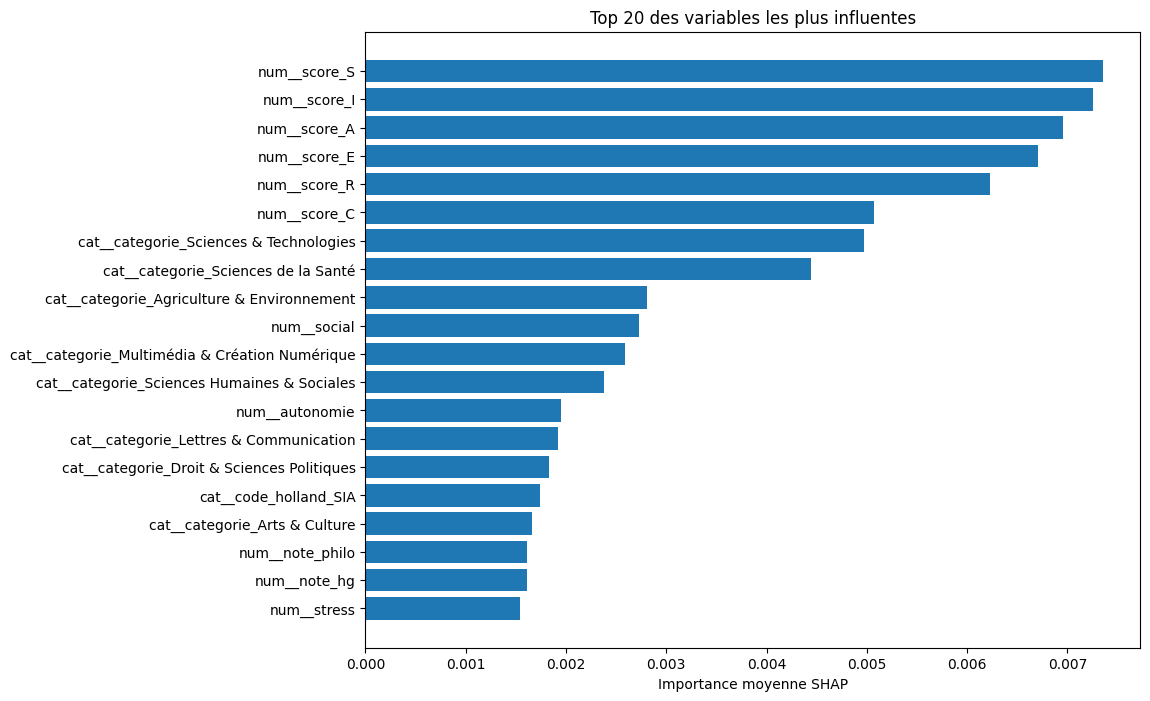

In [121]:
import matplotlib.pyplot as plt

top20 = importance_df.head(20)

plt.figure(figsize=(10,8))

plt.barh(
    top20['Variable'],
    top20['Importance']
)

plt.gca().invert_yaxis()

plt.xlabel("Importance moyenne SHAP")
plt.title("Top 20 des variables les plus influentes")

plt.show()

In [122]:
importance_df[
importance_df['Variable'].str.contains('note|moy')
].sort_values(
by='Importance',
ascending=False
)

,Variable,Importance
3,num__note_philo,0.001616
4,num__note_hg,0.001613
8,num__moy_lettres,0.001506
9,num__moy_globale,0.001019
7,num__moy_sciences,0.000928
0,num__note_maths,0.000897
2,num__note_anglais,0.000692
5,num__note_spe1,0.000571
1,num__note_francais,0.000506
6,num__note_spe2,0.000189



L'analyse d'explicabilité réalisée avec SHAP a permis d'identifier les variables les plus influentes dans les recommandations du modèle Random Forest.

Les résultats montrent que les scores RIASEC (S, I, R, A, E et C) figurent parmi les variables les plus importantes. Cela indique que les centres d'intérêt et les profils vocationnels des élèves jouent un rôle majeur dans la détermination de leur orientation.

Les catégories d'orientation obtenues au premier niveau de prédiction apparaissent également comme des variables fortement influentes. Cela est cohérent avec l'approche hiérarchique adoptée, dans laquelle la catégorie prédite sert à restreindre l'espace des branches possibles.

Les notes académiques (mathématiques, philosophie, histoire-géographie, moyenne globale, moyenne des lettres, moyenne des sciences, etc.) participent également aux prédictions, mais leur influence est plus répartie entre plusieurs variables. Individuellement, leur importance est donc plus faible que celle des scores RIASEC parce que la prédiction se fait à 2 niveaux et que le niveau 2 se base aussi sur les catégories.

Ces résultats montrent que le modèle ne se base pas uniquement sur les performances scolaires, mais combine les résultats académiques avec les intérêts et aptitudes représentés par les scores RIASEC afin de fournir une recommandation plus personnalisée.

 ## Phase finale
 Traitement des données avec le jeu de test 
 

 Pour la prédiction du niveau 2, le modèle utilise désormais réellement la catégorie **prédite** par le niveau 1 (et non la vraie catégorie), en remplaçant explicitement la colonne `categorie` du jeu de test avant le prétraitement. Comme le split est désormais unique, `X_test_cat` et `X_test_branche` correspondent exactement aux mêmes lycéens, ce qui rend le chaînage valide.
 

In [123]:
y_pred_cat_test = rf_model.predict(X_test_cat_processed)

#Reconversion des catégoires en texte
categories_predites = label_encoder_cat.inverse_transform(
    y_pred_cat_test
)

accuracy_cat_test = accuracy_score(y_test_cat, y_pred_cat_test)
print("Accuracy Niveau 1 (catégorie) sur le test set :", accuracy_cat_test)

Accuracy Niveau 1 (catégorie) sur le test set : 1.0


In [124]:
#copions les données du niveau 2
X_test_finale = X_test_branche.copy()

# on remplace la VRAIE catégorie par celle PRÉDITE par le niveau 1.
# seule la catégorie prédite est disponible au moment de recommander une branche.
X_test_finale['categorie'] = categories_predites

In [125]:
#prétraitement
X_test_finale_processed = preprocessor_branche.transform(
    X_test_finale
)

In [126]:
#prédiction
y_pred_finale = rf_model2.predict(
    X_test_finale_processed
)

Evaluation 

In [127]:
accuracy_finale = accuracy_score(
    y_test_branche,
    y_pred_finale
)

print("Accuracy système complet :", accuracy_finale)

Accuracy système complet : 0.9609756097560975


In [128]:
f1_finale = f1_score(
    y_test_branche,
    y_pred_finale,
    average='macro'
)

print("F1 macro système complet :", f1_finale)

F1 macro système complet : 0.9532913845628558


Reconversion des barnches

In [129]:
predictions_finales = label_encoder_branche.inverse_transform(
    y_pred_finale
)

### Analyse de l'impact de l'erreur du niveau 1 sur le niveau 2

À titre de comparaison (juste avoir pour une meilleure analyse), on mesure la performance du niveau 2 si on lui donnait la vraie catégorie au lieu de la catégorie prédite. L'écart entre les deux mesure la dégradation réellement introduite par la cascade.

In [130]:
# Référence : niveau 2 avec la VRAIE catégorie (non disponible en production)
y_pred_reference = rf_model2.predict(X_test_branche_processed)

accuracy_reference = accuracy_score(y_test_branche, y_pred_reference)
f1_reference = f1_score(y_test_branche, y_pred_reference, average='macro')

print("Référence (vraie catégorie)   - Accuracy :", accuracy_reference, "| F1 macro :", f1_reference)
print("Système réel (catégorie prédite) - Accuracy :", accuracy_finale, "| F1 macro :", f1_finale)
print("Écart d'accuracy dû à la cascade :", accuracy_reference - accuracy_finale)

Référence (vraie catégorie)   - Accuracy : 0.9609756097560975 | F1 macro : 0.9532913845628558
Système réel (catégorie prédite) - Accuracy : 0.9609756097560975 | F1 macro : 0.9532913845628558
Écart d'accuracy dû à la cascade : 0.0


## Évaluation du système hiérarchique complet

Afin de simuler le fonctionnement réel du système d'orientation, les catégories prédites par le modèle du premier niveau ont été utilisées comme entrée du second niveau chargé de prédire les branches.

Résultats du système complet (cascade réelle) :
- Accuracy : 96,10 %
- F1-score macro : 95,33 %

Analyse de l'écart introduit par la cascade :
Le niveau 1 atteint une accuracy de 100 % sur le jeu de test, il se trompe donc pas sur la catégorie. En conséquence, l'écart entre le système réel (catégorie prédite) et une évaluation de référence utilisant la vraie catégorie (impossible en production, mesure purement analytique) est nul : les deux donnent exactement 96,10 % d'accuracy et 95,33 % de F1-macro. La cascade n'introduit donc, sur ce jeu de test, aucune dégradation mesurable.

une accuracy de 100 % sur le niveau 1 doit être commentée plutôt que passée sous silence, car elle peut sembler suspecte de prime abord. Elle s'explique ici par la nature du dataset : la catégorie est construite à partir de règles logiques fortement corrélées aux variables d'entrée, ce qui rend la frontière entre les 9 catégories très nette dans des données synthétiques. Ce n'est pas un signe de fuite de données, la colonne branche reste exclue des features du niveau 1, et le split train/val/test est strictement respecté, mais un résultat attendu d'un problème de classification grossier (9 classes bien séparées) sur un dataset construit par règles. Sur des données réelles, une telle perfection ne serait pas attendue

ces excellentes performances s'expliquent en grande partie par le caractère synthétique et fortement corrélé du dataset (règles logiques Holland/O*NET avec seulement 20% de cas "surprenants", bruit gaussien contrôlé). Cependant sur des données réelles de lycéens, plus bruitées et avec des profils plus ambigus, une dégradation de performance est à anticiper. C'est d'ailleurs précisément la raison d'être de la validation humaine par le conseiller d'orientation (Human-in-the-Loop) prévue dans le cahier des charges.

